#### settings

In [1]:
import os, sys, json, csv, math
import re, glob, h5py
from pathlib import Path

import numpy as np
import polars as pl
import seaborn as sns

from scipy.stats import gaussian_kde, linregress
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from scipy.special import gamma

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.animation as animation

from mpl_toolkits.axes_grid1 import ImageGrid
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1 import ImageGrid
from matplotlib.colors import TwoSlopeNorm

In [2]:
## figure width: 3.375in (8.5cm=3.35in) or 7in
## font: 

#mpl.rcParams['mathtext.fontset'] = 'dejavusans'
"""plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.labelsize': 'large',

    'mathtext.fontset': 'custom',
        'mathtext.rm': 'Arial',
        'mathtext.it': 'Arial:italic',
        'mathtext.bf': 'Arial:bold',
        'mathtext.bfit': 'Arial:bold:italic',
        'mathtext.fallback': 'stixsans',

    #* Line width
    'lines.linewidth': 2,       #plot line width
    'axes.linewidth': 1.5,
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,

    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,    
})"""

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 'large',

    'mathtext.fontset': 'custom',
        'mathtext.rm': 'Arial',
        'mathtext.it': 'Arial:italic',
        'mathtext.bf': 'Arial:bold',
        'mathtext.bfit': 'Arial:bold:italic',
        'mathtext.fallback': 'stixsans',

    #* Line width
    'lines.linewidth': 1,       #plot line width
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.minor.width': 0.8,
    'ytick.minor.width': 0.8,

    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3   
})

# MAIN FIGURES

## Dynamics

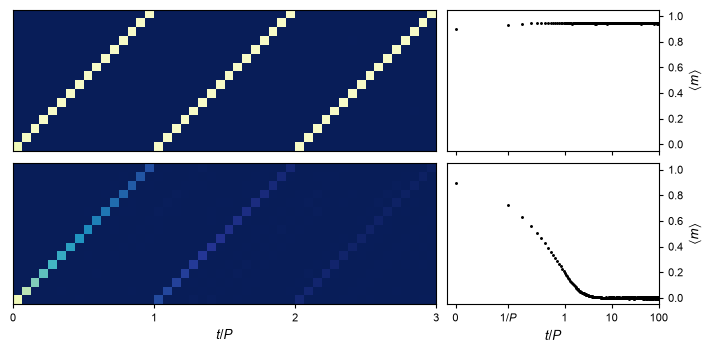

In [73]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(7, 4),
                       layout='compressed', width_ratios=[2, 1])

n_steps = 1601
K = 16
a = 0.03125

for i, temp in enumerate([0.5, 0.95]):
    with h5py.File(f"../_results/_traj_all/p2/N512/a0.03125_T{temp}_m0.9_t1600/traj.h5", 'r') as f:
        #print(f.keys())
        mt = np.array(f['m_t'])[0].T
        m_all = np.array(f['M'])[0].T
        mmean = np.array(f['m_t_mean'])
        mmax = np.array(f['mmax_t_mean'])
        mvar = np.array(f['m_t_var'])
        frac = np.array(f['m_t_retrieval_frac'])

    #ax[i][0].set_axis_off()
        #a.set_xlim(0, steps1)  
    
    ax[i][0].imshow(np.abs(np.mean(m_all, axis=2)), cmap='YlGnBu_r', origin = 'lower',
                extent =[0, n_steps, 0, 16], aspect=1, vmin=0, vmax=1, rasterized=True)

    #for j in range(1, 3):
    #    ax[i][0].axvline(j*16, color='1', lw=1, ls='--')

    ax[i][0].set_xlim(0, 16*3)
    ax[i][0].set_ylim(0, 16)
    ax[i][0].set_yticks([])

    #for s in range(mt.shape[1]):
    #    ax[i][1].scatter(np.arange(n_steps)/16, mt[:, s], label=f"Var m(t), a={a:.3f}", color="xkcd:cerulean blue", alpha=0.002, s=5, rasterized=True)

    ax[i][1].scatter(np.arange(n_steps)/K, mmean, color="0", alpha=1, marker='.', s=5)
    #ax.plot(np.arange(n_steps)/16, mmax, label=f"Var m(t), a={a:.3}", color="red", alpha=1)

    ax[i][1].set_xscale('symlog', linthresh=1/16) 
    ax[i][1].yaxis.tick_right()
    ax[i][1].yaxis.set_label_position('right')   
    ax[i][1].set_ylabel("$\\langle m \\rangle$")
    #ax[i][1].set_title(f"p=2, N=512, m0=1, $\\alpha$=0.03125, T={temp}")
    #ax.legend()
    #ax.set_xscale('log')
    ax[i][1].set_xlim(-0.01, 100)
    ax[i][1].set_ylim(-0.05, 1.05)
    #ax[i][1].grid(True, alpha=0.3)

ax[0][1].set_xticks([0, 1/16, 1, 10, 100],
                    labels=['', '', '', '', ''], minor=False)
ax[0][1].set_xticks([], minor=True)

ax[0][0].set_xticks([])
ax[1][0].set_xticks([0, 16, 32, 48], labels=['0', '1', '2', '3'])

ax[1][0].set_xlabel("$t/P$")
ax[1][1].set_xlabel("$t/P$")

ax[1][1].set_xticks([0, 1/16, 1, 10, 100],
                    labels=['$0$', '$1/P$', '$1$', '$10$', '$100$'], minor=False)
ax[1][1].set_xticks([], minor=True)

plt.savefig("./final/fig1-dynamics/p2_N512_K16.svg", dpi=800)
plt.show()

In [ ]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(3.375, 2),
                       layout='compressed', width_ratios=[5, 2])

n_steps = 1601
K = 16
a = 0.03125

for i, temp in enumerate([0.5, 0.95]):
    with h5py.File(f"../_results/_traj_all/p2/N512/a0.03125_T{temp}_m0.9_t1600/traj.h5", 'r') as f:
        #print(f.keys())
        mt = np.array(f['m_t'])[0].T
        m_all = np.array(f['M'])[0].T
        mmean = np.array(f['m_t_mean'])
        mmax = np.array(f['mmax_t_mean'])
        mvar = np.array(f['m_t_var'])
        frac = np.array(f['m_t_retrieval_frac'])

    ax[i][0].imshow(np.abs(np.mean(m_all, axis=2)), cmap='YlGnBu_r', origin = 'lower',
                extent =[0, n_steps, 0, 16], aspect=1, vmin=0, vmax=1, rasterized=True)

    ax[i][0].set_xlim(0, 16*3)
    ax[i][0].set_ylim(0, 16)
    ax[i][0].set_yticks([])

    ax[i][1].scatter(np.arange(n_steps)/K, mmean, color="0", alpha=1, marker='.', s=5)

    ax[i][1].set_xscale('symlog', linthresh=1/16)

    ax[i][1].set_ylabel("$\\langle m \\rangle$", labelpad=1)
    ax[i][1].set_xlim(-0.01, 100)
    ax[i][1].set_ylim(-0.05, 1.05)
    ax[i][1].set_yticks([0, 1])

#* Heatmap y axis: pattern index
for i in range(2):
    ax[i][0].set_ylabel('Pattern Index', fontsize=8)

#* Panel labels, above the top-left corner of each panel, ordered by row: (a), (b) top; (c), (d) bottom
for (i, j), lab in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ['(a)', '(b)', '(c)', '(d)']):
    ax[i][j].set_title(lab, loc='left', fontsize=8, pad=3)

ax[0][1].set_xticks([0, 1/16, 1, 10, 100],
                    labels=['', '', '', '', ''], minor=False)
ax[0][1].set_xticks([], minor=True)

ax[0][0].set_xticks([0, 16, 32, 48], labels=['', '', '', ''])
ax[1][0].set_xticks([0, 16, 32, 48], labels=['0', '1', '2', '3'])

ax[1][0].set_xlabel("$t$/$P$")
ax[1][1].set_xlabel("$t$/$P$")

# "10" label omitted (tick kept): it collides with "100" at one-column width
ax[1][1].set_xticks([0, 1/16, 1, 10, 100],
                    labels=['$0$', '$1/P$', '$1$', '', '$100$'], minor=False)
ax[1][1].set_xticks([], minor=True)

#* Freeze the layout, then shift every panel right so the content is flush with the right edge
#  (aspect=1 leaves spare width, which the layout would otherwise split between both sides)
fig.canvas.draw()
fig.set_layout_engine('none')
W = fig.get_figwidth()
dx = (W - fig.get_tightbbox(fig.canvas.get_renderer()).x1 - 0.5/72) / W   # keep 0.5 pt margin
for a_ in ax.flat:
    pos = a_.get_position()
    a_.set_position([pos.x0 + dx, pos.y0, pos.width, pos.height])

plt.savefig("./final/fig1-dynamics/p2_N512_K16_small.svg", dpi=800)
plt.show()

## Quasipotential

./final/fig1-quasipotential/fig1_p2_T0.1_PHI.svg


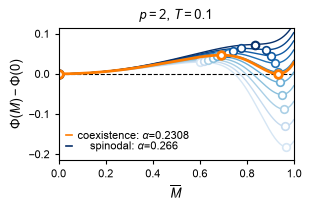

In [95]:
T=0.1

p2_qp = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_p2_T0.1.csv')
p2_qp_ext = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_extrema_p2_T0.1.csv')

phi_min = p2_qp_ext.filter((pl.col('kind')=='local_min') & (pl.col('Phi') != 0))
a_coex = phi_min['alpha'][int(np.argmin(np.abs(phi_min['Phi'])))]
phi_coex = phi_min['Phi'][int(np.argmin(np.abs(phi_min['Phi'])))]
a_spin = p2_qp_ext['alpha'].max()
a_cutoff = p2_qp_ext.filter((pl.col('Phi') < phi_coex-0.2) & (pl.col('kind')=='local_min'))['alpha'].max()

alphas = np.unique(np.concatenate([p2_qp['alpha'].unique()[::5][::-1].to_numpy()[1:], [a_coex, a_spin]]))
alphas.sort()
alphas = alphas[alphas >= a_cutoff]

fig, ax = plt.subplots(figsize=(3, 2), layout='constrained')

blues = mpl.colormaps['Blues'](np.linspace(0, 1, len(alphas[::-1][1:-1])+4))

for i, a in enumerate(alphas):
    subset = p2_qp.filter(pl.col('alpha') == a)

    if a==a_coex:
        ax.plot(subset['M'], subset['Phi'], color = '#FF7C00', label = f"coexistence: $\\alpha$={a:4.4f}", lw=2, zorder = 2.3)
        ax.scatter(p2_qp_ext.filter(pl.col('alpha') == a)['M'], p2_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor='#FF7C00', linewidth = 2, s = 30, zorder = 2.3)

    elif a==a_spin:
        ax.plot(subset['M'], subset['Phi'], color = blues[i+2], label = f"spinodal: $\\alpha$={a:4.3f}")
        ax.scatter([0.832166166], [0.069612091+0.003], color = '1',
                            marker='o', edgecolor=blues[i+2], linewidth = 1.5, s = 30, zorder = 2.2)
        ax.scatter(p2_qp_ext.filter(pl.col('alpha') == a)['M'], p2_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                    marker='o', edgecolor=blues[i+2], linewidth = 2, s = 30, zorder = 2.2)
    else:
        ax.plot(subset['M'], subset['Phi'], color = blues[i+2])
        if a<a_cutoff:
            continue
        ax.scatter(p2_qp_ext.filter(pl.col('alpha') == a)['M'], p2_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor=blues[i+2], linewidth = 1.2, s = 30, zorder = 2.2)

ax.set_title(f"$p=2$, $T={T}$")
ax.set_xlabel("$\\overline{M}$")
ax.set_ylabel("$\\Phi(M) - \\Phi(0)$")
ax.axhline(0.0, color="0", lw=0.8, ls="--", zorder = 0)
#ax.axvline(0.83, color="0", lw=1.5, ls=":", zorder = 0)

#ax.grid(color = '0.8')
ax.set_axisbelow(False)
ax.set_xlim(0, 1)
ax.set_ylim(-(0.2+0.05*0.3), 0.1+0.05*0.3) #(phi_coex-0.2, p2_qp_ext['Phi'].max()+0.05)

legend_obj = ax.legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)

for handle in legend_obj.legend_handles:
    handle.set_linewidth(1.2)

max_shift = max([t.get_window_extent().width for t in legend_obj.get_texts()])
for t in legend_obj.get_texts():
    t.set_ha('right')
    temp_shift = max_shift - t.get_window_extent().width
    if temp_shift > 0:
        t.set_position((temp_shift-10.5, 0))

name = f"./final/fig1-quasipotential/fig1_p2_T{T}_PHI.svg"
print(name)
plt.savefig(name, dpi=800, )
plt.show()

./final/fig1-quasipotential/fig1_p2p3_T0.1_PHI_full.svg


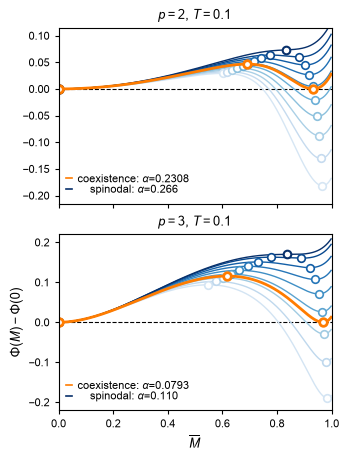

In [109]:
fig, axes = plt.subplots(nrows=2, figsize=(3.375, 4.5), layout='constrained', sharex=True)

ax = axes[0]
ax2 = axes[1]

#* p=2
T=0.1

p2_qp = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_p2_T0.1.csv')
p2_qp_ext = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_extrema_p2_T0.1.csv')

phi_min = p2_qp_ext.filter((pl.col('kind')=='local_min') & (pl.col('Phi') != 0))
a_coex = phi_min['alpha'][int(np.argmin(np.abs(phi_min['Phi'])))]
phi_coex = phi_min['Phi'][int(np.argmin(np.abs(phi_min['Phi'])))]
a_spin = p2_qp_ext['alpha'].max()
a_cutoff = p2_qp_ext.filter((pl.col('Phi') < phi_coex-0.2) & (pl.col('kind')=='local_min'))['alpha'].max()

alphas = np.unique(np.concatenate([p2_qp['alpha'].unique()[::5][::-1].to_numpy()[1:], [a_coex, a_spin]]))
alphas.sort()
alphas = alphas[alphas >= a_cutoff]

blues = mpl.colormaps['Blues'](np.linspace(0, 1, len(alphas[::-1][1:-1])+4))

for i, a in enumerate(alphas):
    subset = p2_qp.filter(pl.col('alpha') == a)

    if a==a_coex:
        ax.plot(subset['M'], subset['Phi'], color = '#FF7C00', label = f"coexistence: $\\alpha$={a:4.4f}", lw=2, zorder = 2.3)
        ax.scatter(p2_qp_ext.filter(pl.col('alpha') == a)['M'], p2_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor='#FF7C00', linewidth = 2, s = 30, zorder = 2.3)

    elif a==a_spin:
        ax.plot(subset['M'], subset['Phi'], color = blues[i+2], label = f"spinodal: $\\alpha$={a:4.3f}")
        ax.scatter([0.832166166], [0.069612091+0.003], color = '1',
                            marker='o', edgecolor=blues[i+2], linewidth = 1.5, s = 30, zorder = 2.2)
        ax.scatter(p2_qp_ext.filter(pl.col('alpha') == a)['M'], p2_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                    marker='o', edgecolor=blues[i+2], linewidth = 2, s = 30, zorder = 2.2)
    else:
        ax.plot(subset['M'], subset['Phi'], color = blues[i+2])
        if a<a_cutoff:
            continue
        ax.scatter(p2_qp_ext.filter(pl.col('alpha') == a)['M'], p2_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor=blues[i+2], linewidth = 1.2, s = 30, zorder = 2.2)

ax.set_title(f"$p=2$, $T={T}$")
ax.axhline(0.0, color="0", lw=0.8, ls="--", zorder = 0)
#ax.axvline(0.83, color="0", lw=1.5, ls=":", zorder = 0)

#ax.grid(color = '0.8')
ax.set_axisbelow(False)
ax.set_xlim(0, 1)
ax.set_ylim(-(0.2+0.05*0.3), 0.1+0.05*0.3) #(phi_coex-0.2, p2_qp_ext['Phi'].max()+0.05)

legend_obj = ax.legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)

for handle in legend_obj.legend_handles:
    handle.set_linewidth(1.2)

max_shift = max([t.get_window_extent().width for t in legend_obj.get_texts()])
for t in legend_obj.get_texts():
    t.set_ha('right')
    temp_shift = max_shift - t.get_window_extent().width
    if temp_shift > 0:
        t.set_position((temp_shift-10.5, 0))

#* p=3

p3_qp = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.1.csv')
p3_qp_ext = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_extrema_p3_T0.1.csv')

T=0.1

phi_min = p3_qp_ext.filter((pl.col('kind')=='local_min') & (pl.col('Phi') != 0))
a_coex = phi_min['alpha'][int(np.argmin(np.abs(phi_min['Phi'])))]
phi_coex = phi_min['Phi'][int(np.argmin(np.abs(phi_min['Phi'])))]
a_spin = 0.10986910646574363 #p3_qp_ext['alpha'].max()
a_cutoff = p3_qp_ext.filter((pl.col('Phi') < phi_coex-0.2) & (pl.col('kind')=='local_min'))['alpha'].max()

alphas = np.unique(np.concatenate([p3_qp['alpha'].unique()[::-4].to_numpy(), [a_coex, a_spin]]))[:-1]
alphas.sort()

if a_cutoff is not None and a_cutoff > alphas.min():
    alphas = alphas[alphas >= a_cutoff]

blues = mpl.colormaps['Blues'](np.linspace(0, 1, len(alphas[::-1][1:-1])+4))

for i, a in enumerate(alphas):
    subset = p3_qp.filter(pl.col('alpha') == a)

    if a==a_coex:
        ax2.plot(subset['M'], subset['Phi'], color = '#FF7C00', label = f"coexistence: $\\alpha$={a:4.4f}", lw=2, zorder = 2.3)
        ax2.scatter(p3_qp_ext.filter(pl.col('alpha') == a)['M'], p3_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor='#FF7C00', linewidth = 2, s = 30, zorder = 2.3)

    elif a==a_spin:
        ax2.plot(subset['M'], subset['Phi'], color = blues[i+2], label = f"spinodal: $\\alpha$={a:4.3f}")
        ax2.scatter([0.83816016], [0.169753219], color = '1',
                    marker='o', edgecolor=blues[i+2], linewidth = 1.5, s = 30, zorder = 2.2)
    else:
        ax2.plot(subset['M'], subset['Phi'], color = blues[i+2])
        ax2.scatter(p3_qp_ext.filter(pl.col('alpha') == a)['M'], p3_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor=blues[i+2], linewidth = 1.2, s = 30, zorder = 2.2)

ax2.set_title(f"$p=3$, $T={T}$")
ax2.set_xlabel("$\\overline{M}$")
ax2.set_ylabel("$\\Phi(M) - \\Phi(0)$")
ax2.axhline(0.0, color="0", lw=0.8, ls="--", zorder = 0)
#ax.axvline(0.83, color="0", lw=1.5, ls=":", zorder = 0)

#ax.grid(color = '0.8')
ax2.set_axisbelow(False)
ax2.set_xlim(0, 1)
ax2.set_ylim(-0.22, 0.22) #(phi_coex-0.2, p3_qp_ext['Phi'].max()+0.05)

legend_obj = ax2.legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)

for handle in legend_obj.legend_handles:
    handle.set_linewidth(1.2)

max_shift = max([t.get_window_extent().width for t in legend_obj.get_texts()])
for t in legend_obj.get_texts():
    t.set_ha('right')
    temp_shift = max_shift - t.get_window_extent().width
    if temp_shift > 0:
        t.set_position((temp_shift-10.5, 0))

name = f"./final/fig1-quasipotential/fig1_p2p3_T{T}_PHI_full.svg"
print(name)
plt.savefig(name, dpi=800, )
plt.show()

./final/fig1-quasipotential/fig1_p3_T0.1_PHI.svg


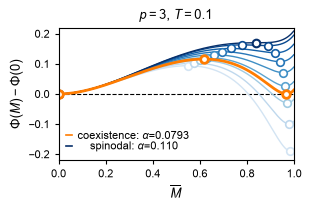

In [87]:
p3_qp = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.1.csv')
p3_qp_ext = pl.read_csv('../Modules/HopfieldSim/_results/quasipotential/quasip_extrema_p3_T0.1.csv')

T=0.1

phi_min = p3_qp_ext.filter((pl.col('kind')=='local_min') & (pl.col('Phi') != 0))
a_coex = phi_min['alpha'][int(np.argmin(np.abs(phi_min['Phi'])))]
phi_coex = phi_min['Phi'][int(np.argmin(np.abs(phi_min['Phi'])))]
a_spin = 0.10986910646574363 #p3_qp_ext['alpha'].max()
a_cutoff = p3_qp_ext.filter((pl.col('Phi') < phi_coex-0.2) & (pl.col('kind')=='local_min'))['alpha'].max()

alphas = np.unique(np.concatenate([p3_qp['alpha'].unique()[::-4].to_numpy(), [a_coex, a_spin]]))[:-1]
alphas.sort()

if a_cutoff is not None and a_cutoff > alphas.min():
    alphas = alphas[alphas >= a_cutoff]

fig, ax = plt.subplots(figsize=(3, 2), layout='constrained')

blues = mpl.colormaps['Blues'](np.linspace(0, 1, len(alphas[::-1][1:-1])+4))

for i, a in enumerate(alphas):
    subset = p3_qp.filter(pl.col('alpha') == a)

    if a==a_coex:
        ax.plot(subset['M'], subset['Phi'], color = '#FF7C00', label = f"coexistence: $\\alpha$={a:4.4f}", lw=2, zorder = 2.3)
        ax.scatter(p3_qp_ext.filter(pl.col('alpha') == a)['M'], p3_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor='#FF7C00', linewidth = 2, s = 30, zorder = 2.3)

    elif a==a_spin:
        ax.plot(subset['M'], subset['Phi'], color = blues[i+2], label = f"spinodal: $\\alpha$={a:4.3f}")
        ax.scatter([0.83816016], [0.169753219], color = '1',
                    marker='o', edgecolor=blues[i+2], linewidth = 1.5, s = 30, zorder = 2.2)
    else:
        ax.plot(subset['M'], subset['Phi'], color = blues[i+2])
        ax.scatter(p3_qp_ext.filter(pl.col('alpha') == a)['M'], p3_qp_ext.filter(pl.col('alpha') == a)['Phi'], color = '1',
                   marker='o', edgecolor=blues[i+2], linewidth = 1.2, s = 30, zorder = 2.2)

ax.set_title(f"$p=3$, $T={T}$")
ax.set_xlabel("$\\overline{M}$")
ax.set_ylabel("$\\Phi(M) - \\Phi(0)$")
ax.axhline(0.0, color="0", lw=0.8, ls="--", zorder = 0)
#ax.axvline(0.83, color="0", lw=1.5, ls=":", zorder = 0)

#ax.grid(color = '0.8')
ax.set_axisbelow(False)
ax.set_xlim(0, 1)
ax.set_ylim(-0.22, 0.22) #(phi_coex-0.2, p3_qp_ext['Phi'].max()+0.05)

legend_obj = ax.legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)

for handle in legend_obj.legend_handles:
    handle.set_linewidth(1.2)

max_shift = max([t.get_window_extent().width for t in legend_obj.get_texts()])
for t in legend_obj.get_texts():
    t.set_ha('right')
    temp_shift = max_shift - t.get_window_extent().width
    if temp_shift > 0:
        t.set_position((temp_shift-10.5, 0))

name = f"./final/fig1-quasipotential/fig1_p3_T{T}_PHI.svg"
print(name)
plt.savefig(name, dpi=800, )
plt.show()

## $T$ vs $\alpha$

### Data

In [ ]:
aT_quasip = pl.read_csv('/home/serim/Projects/HOPFIELD/Workspace/01-theory/_output/phase_diagram_theory.csv')
t2_aT_m = pl.read_csv('../_results/theory/p2_aTgrid_m.csv').rename({"": "T"})
t3_aT_m = pl.read_csv('../_results/theory/p3_aTgrid_m.csv').rename({"": "T"})

### Figures

./final/fig2-aT/aT_m.svg


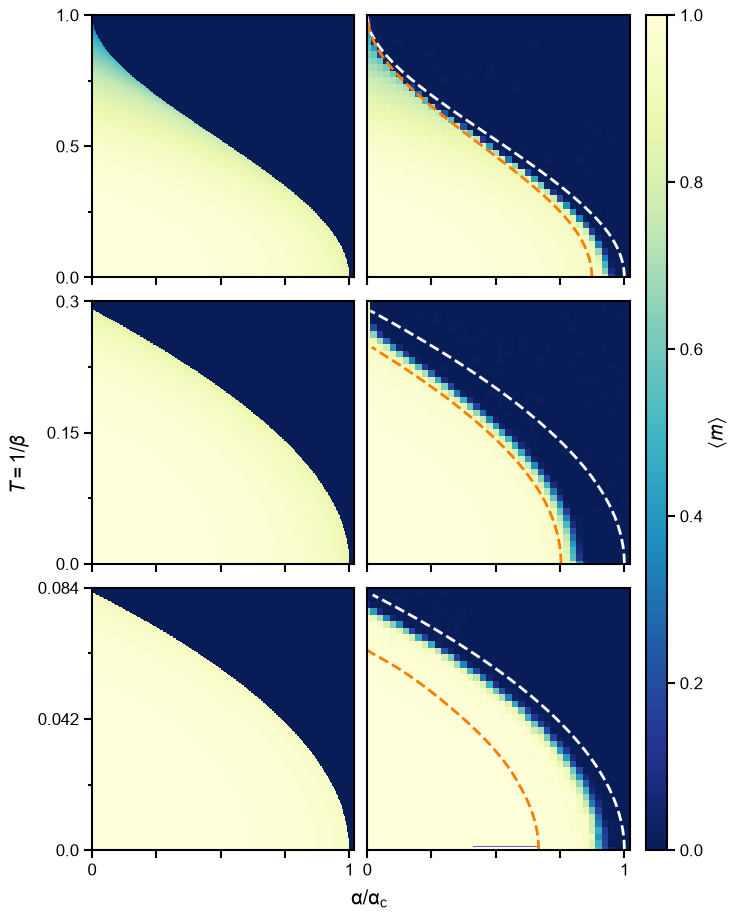

In [287]:
def all_aT(file, kw='m', save_dir='./final/fig2-aT/', name=None, format='.png', colormap='gist_heat'):
    ##% PLOT %##

    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(7, 10), layout='compressed', 
                             sharex=True)
    axes[-1][1].fill_between(np.arange(0, 1, 0.1), 0, 0.001, color='1')
    blank_handles = [mpatches.Rectangle((0, 0), 1, 1, alpha=0, fill=False, linewidth=0) for _ in range(1)]

    assert len(file) == 3
    for i in range(3):

    ##% DATA %##
        folder_name = Path(file[i]).parent.name
        
        pattern = r"aT_p(?P<p>\d+\.?\d*)_N(?P<N>\d+\.?\d*)_m(?P<m>\d+\.?\d*)_t(?P<t>\d+\.?\d*)"
        match = re.search(pattern, folder_name)
    
        if match:
            p = int(match.group('p'))
            N = int(match.group('N'))
            m0 = float(match.group('m'))
            step = int(match.group('t'))
    
        if p==2:
            ac = 0.269
            Tc = 1
        elif p==3:
            ac = 0.126
            Tc = 0.3
        elif p==4:
            ac = 0.033
            Tc = 0.084
                
        df = pl.read_csv(file[i]).unique(subset=['alpha', 'T']).sort(by=['alpha', 'T'])
        mat = df.pivot(index='T', on='alpha', values=kw).to_numpy()[:, 1:]

        tf = pl.read_csv(f'../_results/theory/p{p}_aTgrid_m.csv').rename({"": "T"})
        tmat = tf.to_numpy()[:, 1:]
        tf_a = np.array(tf.columns[1:]).astype(float)
        tf_T = tf['T'].to_numpy()

        for ax in axes[i][:]:
            ax.set_xlim(0, 1.02)
            ax.set_ylim(0, Tc)
            ax.set_aspect(1.02/Tc)

        #norm = mcolors.PowerNorm(gamma=0.5, vmin=0, vmax=1)

        #* Theory
        img = axes[i][0].pcolormesh(tf_a/ac, tf_T, tmat, shading='nearest', #origin='lower', 
                                #aspect=(xlim_high-xtlim_low)/(ylim_high-ytlim_low),
                                #extent=[xtlim_low, xtlim_high, ytlim_low, ytlim_high], 
                                cmap=colormap, edgecolors=None, vmin=0, vmax=1, rasterized=True)

        axes[i][0].set_xticks(np.linspace(0, 1, 5), labels=['0', '', '', '', '1'], minor=False)
        axes[i][0].set_yticks(np.linspace(0, Tc, 3))
        axes[i][0].set_yticks(np.linspace(0, Tc, 5), minor=True)
        #axes[i][0].xaxis.set_major_formatter('{x:.2}')
        axes[i][0].yaxis.set_major_formatter('{x:.4}')

        #axes[i][0].set_xlabel('α/α$_\mathrm{c}$') #, α$_\mathrm{c}$ ≈ ' + f'{ac}')
        #axes[i][0].set_ylabel(f'$T=1/\\beta$')
        #axes[i][0].yaxis.set_label_coords(-0.1, 0.5) 

        #axes[0].set_title(f'p={p}, theory')

        #* Simulation
        if type(colormap) == str:
            colormap = plt.get_cmap(colormap)

        axes[i][1].set_facecolor(colormap(0))

        if p==4:
            xd = np.arange(0.3, 0.7, 0.01)
            axes[i][1].fill_between(xd, 0.0015, 0.045, color=colormap(255))

        img = axes[i][1].pcolormesh(df['alpha'].unique()/ac, df['T'].unique(), mat, shading='nearest', #origin='lower', 
                                    #aspect=(xlim_high-xlim_low)/(ylim_high-ylim_low), 
                                    #extent=[xlim_low, xlim_high, ylim_low, ylim_high], 
                                    cmap=colormap, edgecolors=None, vmin=0, vmax=1, rasterized=True)

        axes[i][1].plot(aT_quasip[f'p{p}_spinodal']/ac, aT_quasip[f'p{p}_T'], label = 'spinodal',
                color='1', ls = '--', dash_joinstyle = 'bevel', alpha=1)
        axes[i][1].plot(aT_quasip[f'p{p}_coexist']/ac, aT_quasip[f'p{p}_T'], label = 'coexistence',
                                color='#FF7C00', ls = '--', dash_joinstyle = 'bevel', alpha=1)

        axes[i][1].set_yticks([])

        #axes[1].legend(labelcolor = '1', labelspacing=0.1, handletextpad=0.5, handlelength=1, 
        #           borderaxespad=0.25, framealpha=0, loc='upper right')
        #axes[1].set_ylabel('T')
        #axes[1].set_title(f'p={p},  N={N},  m(0)={m0}')

    #axes[-1][0].set_xlabel('α/α$_\mathrm{c}$') #, α$_\mathrm{c}$ ≈ ' + f'{ac}')

    #axes[0][0].set_title('theory')
    #axes[0][1].set_title('simulation')

    #axes[0][0].legend(blank_handles, ['p=2'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[0][1].legend(blank_handles, ['N=1024'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[1][0].legend(blank_handles, ['p=3'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[1][1].legend(blank_handles, ['N=128'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[2][0].legend(blank_handles, ['p=4'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[2][1].legend(blank_handles, ['N=256'], borderaxespad=0.1, framealpha=0, labelcolor='1')

    fig.supxlabel('α/α$_\mathrm{c}$', x=0.48, y=0.035, ha='center', va='bottom') #(α=$P/N^{p-1}$)
    fig.supylabel('$T=1/\\beta$', x=-0.02, y=0.45, ha='center', va='bottom')


    #* Colorbar
    cbar = fig.colorbar(img, ax = axes, pad=0.03, aspect=40)
    cbar.set_label("$\\langle m \\rangle$", size='large')

    if name is None:
        name = f'aT_{kw}'

    print(save_dir+name+format)
    plt.savefig(save_dir+name+format, dpi=800, pad_inches=0, bbox_inches='tight')
    plt.show()

res = ["../_results/aT/aT_p2_N1024_m0.9_t200K/p2_grid_summary.csv", 
       "../_results/aT/aT_p3_N128_m0.9_t3K/p3_grid_summary.csv", 
       "../_results/aT/aT_p4_N256_m0.9_t200/p4_grid_summary.csv"]

all_aT(res, kw='m', save_dir='./final/fig2-aT/', name=None, format='.svg', colormap='YlGnBu_r')

In [68]:
1/(64**2), df.filter(pl.col('alpha') > 1/(64**2))

(0.000244140625,
 shape: (1_640, 15)
 ┌─────┬─────┬─────┬─────────┬───┬──────────┬───────────┬──────────┬────────────────┐
 │ p   ┆ i   ┆ j   ┆ alpha   ┆ … ┆ mmax_var ┆ mabs      ┆ mabs_var ┆ retrieval_frac │
 │ --- ┆ --- ┆ --- ┆ ---     ┆   ┆ ---      ┆ ---       ┆ ---      ┆ ---            │
 │ i64 ┆ i64 ┆ i64 ┆ f64     ┆   ┆ f64      ┆ f64       ┆ f64      ┆ f64            │
 ╞═════╪═════╪═════╪═════════╪═══╪══════════╪═══════════╪══════════╪════════════════╡
 │ 3   ┆ 2   ┆ 0   ┆ 0.00315 ┆ … ┆ 0.0      ┆ 1.0       ┆ 0.0      ┆ 1.0            │
 │ 3   ┆ 2   ┆ 1   ┆ 0.00315 ┆ … ┆ 0.0      ┆ 1.0       ┆ 0.0      ┆ 1.0            │
 │ 3   ┆ 2   ┆ 2   ┆ 0.00315 ┆ … ┆ 0.0      ┆ 1.0       ┆ 0.0      ┆ 1.0            │
 │ 3   ┆ 2   ┆ 3   ┆ 0.00315 ┆ … ┆ 0.0      ┆ 1.0       ┆ 0.0      ┆ 1.0            │
 │ 3   ┆ 2   ┆ 4   ┆ 0.00315 ┆ … ┆ 0.0      ┆ 1.0       ┆ 0.0      ┆ 1.0            │
 │ …   ┆ …   ┆ …   ┆ …       ┆ … ┆ …        ┆ …         ┆ …        ┆ …              │
 │ 3   ┆ 41  ┆ 36

./final/fig2-aT/aT_m_N64_t1K.png


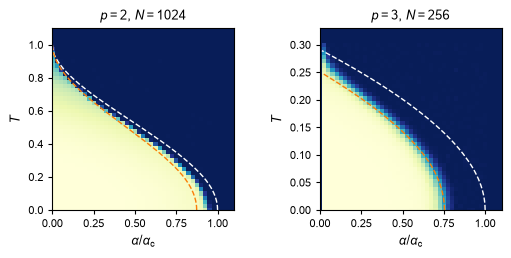

In [69]:
fig, axes = plt.subplots(ncols=2, figsize=(5,3.5), 
                         layout='compressed', gridspec_kw = {'wspace':0.15}, 
                         sharex=True)
       
blank_handles = [mpatches.Rectangle((0, 0), 1, 1, alpha=0, fill=False, linewidth=0) for _ in range(1)]

file = ["../_results/aT/p2/aT_p2_N1024_m0.9_t200K/p2_grid_summary.csv", 
       "../_results/aT/p3/aT_p3_N64_m1_t1K/p3_grid_summary.csv"]
kw = 'm'

for i in range(2):

##% DATA %##
    folder_name = Path(file[i]).parent.name
    
    pattern = r"aT_p(?P<p>\d+\.?\d*)_N(?P<N>\d+\.?\d*)_m(?P<m>\d+\.?\d*)_t(?P<t>\d+\.?\d*)"
    match = re.search(pattern, folder_name)

    if match:
        p = int(match.group('p'))
        N = int(match.group('N'))
        m0 = float(match.group('m'))
        step = int(match.group('t'))

    if p==2:
        ac = 0.269
        Tc = 1
    elif p==3:
        ac = 0.126
        Tc = 0.3
    elif p==4:
        ac = 0.033
        Tc = 0.084
            
    df = pl.read_csv(file[i]).unique(subset=['alpha', 'T']).sort(by=['alpha', 'T'])
    df = df.filter(pl.col('alpha') > 1/(64**2))
    mat = df.pivot(index='T', on='alpha', values=kw).fill_null(0).to_numpy()[:, 1:] #

    tf = pl.read_csv(f'../_results/theory/p{p}_aTgrid_m.csv').rename({"": "T"})
    tmat = tf.to_numpy()[:, 1:]
    tf_a = np.array(tf.columns[1:]).astype(float)
    tf_T = tf['T'].to_numpy()

    scale = 1.1
    axes[i].set_xlim(0, scale)
    axes[i].set_ylim(0, scale*Tc)
    axes[i].set_aspect(1/Tc)

    if p==2:
        axes[i].set_yticks(np.linspace(0, Tc, 6))
    elif p==3:
            axes[i].set_yticks(np.linspace(0, Tc, 7))

    #* Simulation
    colormap = plt.get_cmap('YlGnBu_r')

    axes[i].set_facecolor(colormap(-1))
    img = axes[i].pcolormesh((df['K'].unique()/N**(p-1))/ac, df['T'].unique(), mat, shading='nearest', 
                                cmap=colormap, edgecolors=None, vmin=0, vmax=1, rasterized=True)

    axes[i].plot(aT_quasip[f'p{p}_spinodal']/ac, aT_quasip[f'p{p}_T'], label = 'spinodal',
            color='1', ls = '--', dash_joinstyle = 'bevel', alpha=1)
    axes[i].plot(aT_quasip[f'p{p}_coexist']/ac, aT_quasip[f'p{p}_T'], label = 'coexistence',
                            color='xkcd:pumpkin orange', ls = '--', dash_joinstyle = 'bevel', alpha=1)

axes[0].set_title('$p=2$, $N=1024$')
axes[1].set_title('$p=3$, $N=256$')

axes[0].set_xlabel('$\\alpha/\\alpha_\mathrm{c}$')
axes[1].set_xlabel('$\\alpha/\\alpha_\mathrm{c}$')
axes[0].set_ylabel('$T$') #, x=0.0, y=0.515, ha='center', va='center')
axes[1].set_ylabel('$T$')

save_dir='./final/fig2-aT/'
name = f'aT_{kw}_N64_t1K'
format = '.png'

print(save_dir+name+format)
plt.savefig(save_dir+name+format, dpi=800, pad_inches=0.02, bbox_inches='tight')
plt.show()

./final/fig2-aT/aT_m_theory_marked.png


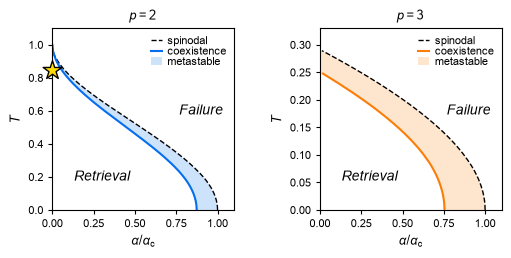

In [ ]:
fig, axes = plt.subplots(ncols=2, figsize=(5, 3.5), 
                         layout='compressed', gridspec_kw = {'wspace':0.15},
                         sharex=True)
       
blank_handles = [mpatches.Rectangle((0, 0), 1, 1, alpha=0, fill=False, linewidth=0) for _ in range(1)]

file = ["../_results/aT/aT_p2_N1024_m0.9_t200K/p2_grid_summary.csv", 
       "../_results/aT/aT_p3_N256_m0.9_t5K/p3_grid_summary.csv"]
kw = 'm'
colors = ['xkcd:cerulean blue', 'xkcd:pumpkin orange']

for i in range(2):

##% DATA %##
    folder_name = Path(file[i]).parent.name
    
    pattern = r"aT_p(?P<p>\d+\.?\d*)_N(?P<N>\d+\.?\d*)_m(?P<m>\d+\.?\d*)_t(?P<t>\d+\.?\d*)"
    match = re.search(pattern, folder_name)

    if match:
        p = int(match.group('p'))
        N = int(match.group('N'))
        m0 = float(match.group('m'))
        step = int(match.group('t'))

    if p==2:
        ac = 0.269
        Tc = 1
    elif p==3:
        ac = 0.126
        Tc = 0.3
    elif p==4:
        ac = 0.033
        Tc = 0.084
            
    df = pl.read_csv(file[i]).unique(subset=['alpha', 'T']).sort(by=['alpha', 'T'])
    mat = df.pivot(index='T', on='alpha', values=kw).fill_null(0).to_numpy()[:, 1:] #

    tf = pl.read_csv(f'../_results/theory/p{p}_aTgrid_m.csv').rename({"": "T"})
    tmat = tf.to_numpy()[:, 1:]
    tf_a = np.array(tf.columns[1:]).astype(float)
    tf_T = tf['T'].to_numpy()

    scale = 1.1
    axes[i].set_xlim(0, scale)
    axes[i].set_ylim(0, scale*Tc)
    axes[i].set_aspect(1/Tc)

    if p==2:
        axes[i].set_yticks(np.linspace(0, Tc, 6))
    elif p==3:
            axes[i].set_yticks(np.linspace(0, Tc, 7))

    #norm = mcolors.PowerNorm(gamma=0.5, vmin=0, vmax=1)

    colormap = plt.get_cmap('YlGnBu_r')

    #* Theory
    #img = axes[i].pcolormesh(tf_a/ac, tf_T, tmat, shading='nearest', 
    #                        cmap='YlGnBu_r', edgecolors=None, vmin=0, vmax=1, rasterized=True)

    axes[i].plot(aT_quasip[f'p{p}_spinodal']/ac, aT_quasip[f'p{p}_T'], label = 'spinodal',
                color='0', ls = '--', dash_joinstyle = 'bevel', alpha=1)
    axes[i].plot(aT_quasip[f'p{p}_coexist']/ac, aT_quasip[f'p{p}_T'], label = 'coexistence',
                color=colors[i], ls = '-', dash_joinstyle = 'bevel', alpha=1, lw=1.5)
    axes[i].fill_betweenx(aT_quasip[f'p{p}_T'], aT_quasip[f'p{p}_spinodal']/ac, aT_quasip[f'p{p}_coexist']/ac, color=colors[i], alpha=0.2, label = 'metastable', edgecolor='none')

    if p==3:
        axes[i].fill_betweenx(aT_quasip[f'p{p}_T'][119:], 0, aT_quasip[f'p{p}_spinodal'][119:]/ac, color=colors[i], alpha=0.2, edgecolor='none')

    axes[i].text(0.3, 0.2*Tc, f'Retrieval', color='0', 
                 fontsize=10, fontstyle='italic', #fontfamily='serif',
                 ha='center', va='center')
    
    axes[i].text(0.9, 0.6*Tc, f'Failure', color='0', 
                     fontsize=10, fontstyle='italic', #fontfamily='serif',
                     ha='center', va='center')

    axes[i].legend(framealpha=0, loc = 'upper right',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

#axes[0].scatter(np.array([0])/0.269, [0.85], marker='*', color='xkcd:sunflower yellow', s=200, 
#                edgecolor='0', linewidths=1,
#                zorder=3, clip_on=False)

#axes[1].scatter(np.array([0])/0.128, [0.26], marker='*', color='yellow', s=100, edgecolor='0', linewidths=1, zorder=3, clip_on=False)
    
axes[0].set_title('$p=2$')
axes[1].set_title('$p=3$')

axes[0].set_xlabel('$\\alpha/\\alpha_\mathrm{c}$')
axes[1].set_xlabel('$\\alpha/\\alpha_\mathrm{c}$') #, x=0.475, y=0.05, ha='center', va='bottom') #(α=$P/N^{p-1}$)
axes[0].set_ylabel('$T$') #, x=0.0, y=0.515, ha='center', va='center')
axes[1].set_ylabel('$T$')

save_dir='./final/fig2-aT/'
name = f'aT_{kw}_theory'
format = '.png'

print(save_dir+name+format)
plt.savefig(save_dir+name+format, dpi=800, pad_inches=0.02, bbox_inches='tight')
plt.show()

/tmp/ipykernel_1393241/3045058250.py:115: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.draw()


./final/fig2-aT/aT_m_small.svg


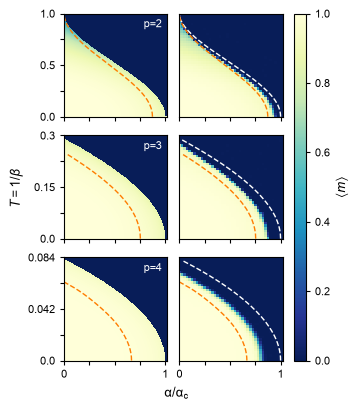

In [53]:
def all_aT(file, kw='m', save_dir='./final/fig2-aT/', name=None, format='.png', colormap='gist_heat'):
    ##% PLOT %##

    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(3.375, 6), layout='compressed', 
                             sharex=True)
       
    blank_handles = [mpatches.Rectangle((0, 0), 1, 1, alpha=0, fill=False, linewidth=0) for _ in range(1)]

    assert len(file) == 3
    for i in range(3):

    ##% DATA %##
        folder_name = Path(file[i]).parent.name
        
        pattern = r"aT_p(?P<p>\d+\.?\d*)_N(?P<N>\d+\.?\d*)_m(?P<m>\d+\.?\d*)_t(?P<t>\d+\.?\d*)"
        match = re.search(pattern, folder_name)
    
        if match:
            p = int(match.group('p'))
            N = int(match.group('N'))
            m0 = float(match.group('m'))
            step = int(match.group('t'))
    
        if p==2:
            ac = 0.269
            Tc = 1
        elif p==3:
            ac = 0.126
            Tc = 0.3
        elif p==4:
            ac = 0.033
            Tc = 0.084
                
        df = pl.read_csv(file[i]).unique(subset=['alpha', 'T']).sort(by=['alpha', 'T'])
        mat = df.pivot(index='T', on='alpha', values=kw).fill_null(0).to_numpy()[:, 1:] #

        tf = pl.read_csv(f'../_results/theory/p{p}_aTgrid_m.csv').rename({"": "T"})
        tmat = tf.to_numpy()[:, 1:]
        tf_a = np.array(tf.columns[1:]).astype(float)
        tf_T = tf['T'].to_numpy()

        for ax in axes[i][:]:
            ax.set_xlim(0, 1.02)
            ax.set_ylim(0, Tc)
            ax.set_aspect(1.02/Tc)

        #norm = mcolors.PowerNorm(gamma=0.5, vmin=0, vmax=1)

        #* Theory
        img = axes[i][0].pcolormesh(tf_a/ac, tf_T, tmat, shading='nearest', #origin='lower', 
                                #aspect=(xlim_high-xtlim_low)/(ylim_high-ytlim_low),
                                #extent=[xtlim_low, xtlim_high, ytlim_low, ytlim_high], 
                                cmap=colormap, edgecolors=None, vmin=0, vmax=1, rasterized=True)

    
        axes[i][0].plot(aT_quasip[f'p{p}_coexist']/ac, aT_quasip[f'p{p}_T'], label = 'coexistence',
                                        color='#FF7C00', ls = '--', dash_joinstyle = 'bevel', alpha=1)

        axes[i][0].set_xticks(np.linspace(0, 1, 5), labels=['0', '', '', '', '1'], minor=False)
        axes[i][0].set_yticks(np.linspace(0, Tc, 3))
        axes[i][0].set_yticks(np.linspace(0, Tc, 5), minor=True)
        #axes[i][0].xaxis.set_major_formatter('{x:.2}')
        axes[i][0].yaxis.set_major_formatter('{x:>6.4}')

        #axes[i][0].set_xlabel('α/α$_\mathrm{c}$') #, α$_\mathrm{c}$ ≈ ' + f'{ac}')
        #axes[i][0].set_ylabel(f'$T=1/\\beta$')
        #axes[i][0].yaxis.set_label_coords(-0.1, 0.5) 

        #axes[0].set_title(f'p={p}, theory')

        #* Simulation
        if type(colormap) == str:
            colormap = plt.get_cmap(colormap)

        axes[i][1].set_facecolor('red')
        img = axes[i][1].pcolormesh((df['K'].unique()/N**(p-1))/ac, df['T'].unique(), mat, shading='nearest', #origin='lower', 
                                    #aspect=(xlim_high-xlim_low)/(ylim_high-ylim_low), 
                                    #extent=[xlim_low, xlim_high, ylim_low, ylim_high], 
                                    cmap=colormap, edgecolors=None, vmin=0, vmax=1, rasterized=True)

        axes[i][1].plot(aT_quasip[f'p{p}_spinodal']/ac, aT_quasip[f'p{p}_T'], label = 'spinodal',
                color='1', ls = '--', dash_joinstyle = 'bevel', alpha=1)
        axes[i][1].plot(aT_quasip[f'p{p}_coexist']/ac, aT_quasip[f'p{p}_T'], label = 'coexistence',
                                color='#FF7C00', ls = '--', dash_joinstyle = 'bevel', alpha=1)

        axes[i][1].set_yticks([])
        axes[i][0].text(-0.15, 0.5, '0.000', transform=axes[i][0].transAxes, 
                            alpha=0, va='center', ha='right')

        #axes[1].legend(labelcolor = '1', labelspacing=0.1, handletextpad=0.5, handlelength=1, 
        #           borderaxespad=0.25, framealpha=0, loc='upper right')
        #axes[1].set_ylabel('T')
        #axes[1].set_title(f'p={p},  N={N},  m(0)={m0}')

    #axes[-1][0].set_xlabel('α/α$_\mathrm{c}$') #, α$_\mathrm{c}$ ≈ ' + f'{ac}')

    #axes[0][0].set_title('theory')
    #axes[0][1].set_title('simulation')

    axes[0][0].legend(blank_handles, ['p=2'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[0][1].legend(blank_handles, ['N=1024'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    axes[1][0].legend(blank_handles, ['p=3'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[1][1].legend(blank_handles, ['N=128'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    axes[2][0].legend(blank_handles, ['p=4'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[2][1].legend(blank_handles, ['N=256'], borderaxespad=0.1, framealpha=0, labelcolor='1')

    fig.supxlabel('α/α$_\mathrm{c}$', x=0.475, y=0.05, ha='center', va='bottom') #(α=$P/N^{p-1}$)
    fig.supylabel('$T=1/\\beta$', x=0.0, y=0.515, ha='center', va='center')


    #* Colorbar
    cbar = fig.colorbar(img, ax = axes, pad=0.05, aspect=30)
    cbar.set_label("$\\langle m \\rangle$", size='large')

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    bbox = fig.get_tightbbox(renderer)

    fig.set_figheight(bbox.height)

    if name is None:
        name = f'aT_{kw}_small'

    print(save_dir+name+format)
    plt.savefig(save_dir+name+format, dpi=800, pad_inches=0, bbox_inches='tight')
    plt.show()

res = ["../_results/aT/p2/aT_p2_N1024_m0.9_t200K/p2_grid_summary.csv", 
       "../_results/aT/p3/aT_p3_N256_m0.9_t5K/p3_grid_summary.csv", 
       "../_results/aT/p4/aT_p4_N128_m0.9_t1000/p4_grid_summary.csv"]

all_aT(res, kw='m', save_dir='./final/fig2-aT/', name=None, format='.svg', colormap='YlGnBu_r')

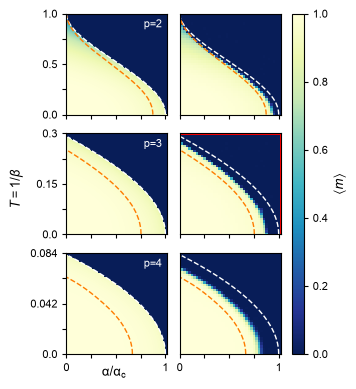

In [94]:
def all_aT(file, kw='m', save_dir='./final/fig2-aT/', name=None, format='.png', colormap='gist_heat'):
    ##% PLOT %##

    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(3.375, 6), layout='compressed', 
                             sharex=True)
       
    blank_handles = [mpatches.Rectangle((0, 0), 1, 1, alpha=0, fill=False, linewidth=0) for _ in range(1)]

    assert len(file) == 3
    for i in range(3):

    ##% DATA %##
        folder_name = Path(file[i]).parent.name
        
        pattern = r"aT_p(?P<p>\d+\.?\d*)_N(?P<N>\d+\.?\d*)_m(?P<m>\d+\.?\d*)_t(?P<t>\d+\.?\d*)"
        match = re.search(pattern, folder_name)
    
        if match:
            p = int(match.group('p'))
            N = int(match.group('N'))
            m0 = float(match.group('m'))
            step = int(match.group('t'))
    
        if p==2:
            ac = 0.269
            Tc = 1
        elif p==3:
            ac = 0.126
            Tc = 0.3
        elif p==4:
            ac = 0.033
            Tc = 0.084
                
        df = pl.read_csv(file[i]).unique(subset=['alpha', 'T']).sort(by=['alpha', 'T'])
        mat = df.pivot(index='T', on='alpha', values=kw).fill_null(0).to_numpy()[:, 1:] #

        tf = pl.read_csv(f'../_results/theory/p{p}_aTgrid_m.csv').rename({"": "T"})
        tmat = tf.to_numpy()[:, 1:]
        tf_a = np.array(tf.columns[1:]).astype(float)
        tf_T = tf['T'].to_numpy()

        for ax in axes[i][:]:
            ax.set_xlim(0, 1.02)
            ax.set_ylim(0, Tc)
            ax.set_aspect(1.02/Tc)

        #norm = mcolors.PowerNorm(gamma=0.5, vmin=0, vmax=1)

        #* Theory
        img = axes[i][0].pcolormesh(tf_a/ac, tf_T, tmat, shading='nearest', #origin='lower', 
                                #aspect=(xlim_high-xtlim_low)/(ylim_high-ytlim_low),
                                #extent=[xtlim_low, xtlim_high, ytlim_low, ytlim_high], 
                                cmap=colormap, edgecolors=None, vmin=0, vmax=1, rasterized=True)

        axes[i][0].plot(aT_quasip[f'p{p}_spinodal']/ac, aT_quasip[f'p{p}_T'], label = 'spinodal',
                        color='1', ls = '--', dash_joinstyle = 'bevel', alpha=1)
        axes[i][0].plot(aT_quasip[f'p{p}_coexist']/ac, aT_quasip[f'p{p}_T'], label = 'coexistence',
                                        color='#FF7C00', ls = '--', dash_joinstyle = 'bevel', alpha=1)

        axes[i][0].set_xticks(np.linspace(0, 1, 5), labels=['0', '', '', '', '1'], minor=False)
        axes[i][0].set_yticks(np.linspace(0, Tc, 3))
        axes[i][0].set_yticks(np.linspace(0, Tc, 5), minor=True)
        #axes[i][0].xaxis.set_major_formatter('{x:.2}')
        axes[i][0].yaxis.set_major_formatter('{x:>6.4}')

        #axes[i][0].set_xlabel('α/α$_\mathrm{c}$') #, α$_\mathrm{c}$ ≈ ' + f'{ac}')
        #axes[i][0].set_ylabel(f'$T=1/\\beta$')
        #axes[i][0].yaxis.set_label_coords(-0.1, 0.5) 

        #axes[0].set_title(f'p={p}, theory')

        #* Simulation
        if type(colormap) == str:
            colormap = plt.get_cmap(colormap)

        axes[i][1].set_facecolor('red')
        img = axes[i][1].pcolormesh((df['K'].unique()/N**(p-1))/ac, df['T'].unique(), mat, shading='nearest', #origin='lower', 
                                    #aspect=(xlim_high-xlim_low)/(ylim_high-ylim_low), 
                                    #extent=[xlim_low, xlim_high, ylim_low, ylim_high], 
                                    cmap=colormap, edgecolors=None, vmin=0, vmax=1, rasterized=True)

        axes[i][1].plot(aT_quasip[f'p{p}_spinodal']/ac, aT_quasip[f'p{p}_T'], label = 'spinodal',
                color='1', ls = '--', dash_joinstyle = 'bevel', alpha=1)
        axes[i][1].plot(aT_quasip[f'p{p}_coexist']/ac, aT_quasip[f'p{p}_T'], label = 'coexistence',
                                color='#FF7C00', ls = '--', dash_joinstyle = 'bevel', alpha=1)

        axes[i][1].set_yticks([])
        axes[i][0].text(-0.15, 0.5, '0.000', transform=axes[i][0].transAxes, 
                            alpha=0, va='center', ha='right')

        #axes[1].legend(labelcolor = '1', labelspacing=0.1, handletextpad=0.5, handlelength=1, 
        #           borderaxespad=0.25, framealpha=0, loc='upper right')
        #axes[1].set_ylabel('T')
        #axes[1].set_title(f'p={p},  N={N},  m(0)={m0}')

    #axes[-1][0].set_xlabel('α/α$_\mathrm{c}$') #, α$_\mathrm{c}$ ≈ ' + f'{ac}')

    #axes[0][0].set_title('theory')
    #axes[0][1].set_title('simulation')

    axes[0][0].legend(blank_handles, ['p=2'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[0][1].legend(blank_handles, ['N=1024'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    axes[1][0].legend(blank_handles, ['p=3'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[1][1].legend(blank_handles, ['N=128'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    axes[2][0].legend(blank_handles, ['p=4'], borderaxespad=0.1, framealpha=0, labelcolor='1')
    #axes[2][1].legend(blank_handles, ['N=256'], borderaxespad=0.1, framealpha=0, labelcolor='1')

    axes[-1][0].set_xlabel('α/α$_\mathrm{c}$', x=0.475, y=0.05, ha='center', va='bottom') #(α=$P/N^{p-1}$)
    fig.supylabel('$T=1/\\beta$', x=0.0, y=0.515, ha='center', va='center')


    #* Colorbar
    cbar = fig.colorbar(img, ax = axes, pad=0.05, aspect=30)
    cbar.set_label("$\\langle m \\rangle$", size='large')

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    bbox = fig.get_tightbbox(renderer)

    fig.set_figheight(bbox.height)

    if name is None:
        name = f'aT_{kw}_small'

    #print(save_dir+name+format)
    #plt.savefig(save_dir+name+format, dpi=800, pad_inches=0, bbox_inches='tight')
    plt.show()

res = ["../_results/aT/aT_p2_N1024_m0.9_t200K/p2_grid_summary.csv", 
       "../_results/aT/aT_p3_N256_m0.9_t5K/p3_grid_summary.csv", 
       "../_results/aT/aT_p4_N128_m0.9_t1000/p4_grid_summary.csv"]

all_aT(res, kw='m', save_dir='./final/fig2-aT/', name=None, format='.svg', colormap='YlGnBu_r')

## Distribution

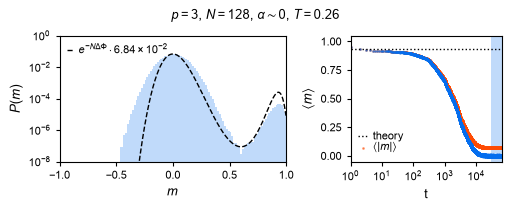

In [ ]:
N=128

with h5py.File(f"..//_results/_traj_all/p3_K1/N128/a6.103515625e-5_T0.26_m1_t500N/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])

n_steps = mt.shape[0]
trials = mt.shape[1]

mdist = mt[30000:, :].flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
prob_m = counts/len(mdist)

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

sns.histplot(x=bin_centers, bins=bin_edges.tolist(), weights=prob_m, color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25)

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("$P(m)$")
ax[0].set_xlim(-1, 1)
#ax.set_ylim(2e-5, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
ax[0].set_yscale('log')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.26.csv")
qp = qp.filter((pl.col("alpha") == 0))

data = np.exp(-qp['Phi'].to_numpy()*N)
y_data = qp['M'].to_numpy()
normalize = 1/np.sum(data*y_data)
exponent = np.floor(np.log10(normalize/data.max()))
pref = normalize/(10**exponent)
y_qp = data*normalize

ax[0].plot(qp['M'].to_numpy(), y_qp, 
        label=f"$e^{{-N\\Delta\\Phi}}\\cdot{pref:.2f}\\times 10^{{ {exponent:.0f} }}$", 
        color="0", ls='--')

ax[0].legend(framealpha=0, loc = 'upper left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)
ax[0].set_ylim(1e-8, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.8)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls=':', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[30000], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].scatter(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$', s=1, edgecolor=None, alpha=0.5)
ax[1].scatter(steps, mmean, color='xkcd:cerulean blue', s=1, edgecolor=None, alpha=0.5) #, s=1)

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 4, 5, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 0.8, borderpad = 0.2,
          labelspacing = 0)

fig.suptitle(f"$p=3$, $N={N}$, $\\alpha\\sim 0$, $T=0.26$")

#ax.set_ylim(0, 9)
plt.savefig(f'/home/serim/Projects/HOPFIELD/_figures/final/distribution/p3_N{N}_K1_T0.26.png', dpi=800, bbox_inches='tight')
plt.show()

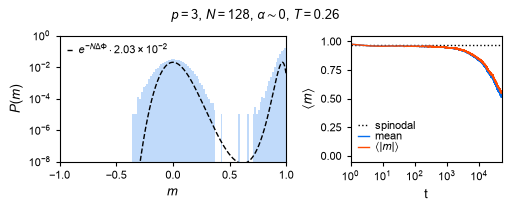

In [38]:
N=128

with h5py.File(f"..//_results/_traj_all/p3/N128/a0.08_T0.1_m1_t50000/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])

n_steps = mt.shape[0]
trials = mt.shape[1]

mdist = mt[-100:, :].flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
prob_m = counts/len(mdist)

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

sns.histplot(x=bin_centers, bins=bin_edges.tolist(), weights=prob_m, color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25)

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("$P(m)$")
ax[0].set_xlim(-1, 1)
#ax.set_ylim(2e-5, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
ax[0].set_yscale('log')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.1.csv")
qp = qp.filter((pl.col("alpha") == 0.0792733719109852)) #0.08539251882193688)) #0.0792733719109852))

data = np.exp(-qp['Phi'].to_numpy()*N)
y_data = qp['M'].to_numpy()
normalize = 1/np.sum(data*y_data)
exponent = np.floor(np.log10(normalize/data.max()))
pref = normalize/(10**exponent)
y_qp = data*peak/data.max()

ax[0].plot(qp['M'].to_numpy(), y_qp, 
        label=f"$e^{{-N\\Delta\\Phi}}\\cdot{pref:.2f}\\times 10^{{ {exponent:.0f} }}$", 
        color="0", ls='--')

ax[0].legend(framealpha=0, loc = 'upper left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)
ax[0].set_ylim(1e-8, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.8)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls=':', label='spinodal')

ax[1].fill_betweenx([-0.05, 1.05], steps[-100], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, label='mean', color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$')

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 4, 5, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

fig.suptitle(f"$p=3$, $N={N}$, $\\alpha\\sim 0$, $T=0.26$")

#ax.set_ylim(0, 9)
#plt.savefig(f'./final/distribution/p3_N{N}_a0.085_T0.1.png', dpi=800, bbox_inches='tight')
plt.show()

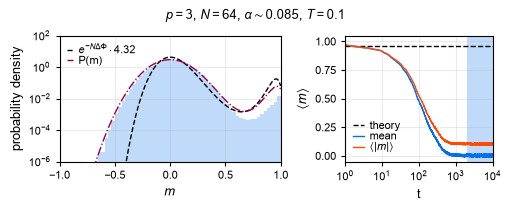

In [137]:
N=64

with h5py.File(f"../_results/_traj_all/p3/N64/a0.085_T0.1_m1_t10000/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])

df = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_p3_N64_T0.1_alpha0.085.csv")

n_steps = mt.shape[0]
trials = mt.shape[1]

cut = 8000
mdist = mt[-cut:, :].flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=True)
prob_m = counts#/len(mdist)

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

sns.histplot(x=bin_centers, bins=bin_edges.tolist(), weights=prob_m, color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25)

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("probability density")
ax[0].set_xlim(-1, 1)
#ax.set_ylim(2e-5, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
ax[0].set_yscale('log')

ax[0].axhline(1/len(mdist), color='xkcd:cerulean blue', ls=':')


qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.1.csv")
qp = qp.filter((pl.col("alpha") == 0.08539251882193688)) #0.0792733719109852))0.08539251882193688

data = np.exp(-qp['Phi'].to_numpy()*N)
y_data = qp['M'].to_numpy()
normalize = 1/np.sum(data*(qp['M'].to_numpy()[1:] - qp['M'].to_numpy()[:-1])[0])
exponent = np.floor(np.log10(normalize/data.max()))
pref = normalize/(10**exponent)
y_qp = data*normalize

ax[0].plot(qp['M'].to_numpy(), y_qp, 
        label=f"$e^{{-N\\Delta\\Phi}}\\cdot{pref:.2f}$", #\\times 10^{{ {exponent:.0f} }}$", 
        color="0", ls='--')

ax[0].plot(df['M'].to_numpy(), df['pi'].to_numpy()/(df['M'].to_numpy()[1:] - df['M'].to_numpy()[:-1])[0], label=f"P(m)", color='xkcd:purple red', ls='-.')

ax[0].legend(framealpha=0, loc = 'upper left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)
ax[0].set_ylim(1e-6, 100)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.8)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls='--', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[-cut], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, label='mean', color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$')

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 4, 5, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

ax[0].grid(alpha=0.25)
ax[1].grid(alpha=0.25)

fig.suptitle(f"$p=3$, $N={N}$, $\\alpha\\sim 0.085$, $T=0.1$")

#ax.set_ylim(0, 9)
plt.savefig(f'./final/distribution/p3_N{N}_a0.085_T0.1_LD.png', dpi=800, bbox_inches='tight')
plt.show()

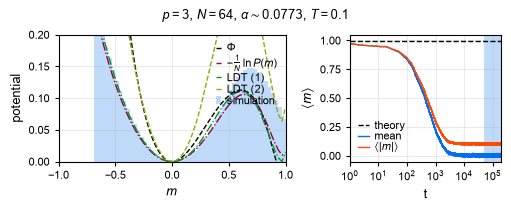

In [46]:
N=64

with h5py.File(f"../_results/_traj_all/p3/N64/a0.0773_T0.1_m1_t200000/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])

df = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_p3_N64_T0.1_alpha0.0773.csv")
df2 = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_case2_p3_N64_T0.1_alpha0.0773.csv")

n_steps = mt.shape[0]
trials = mt.shape[1]

cut = 50000
mdist = mt[cut:, :].flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
prob_m = counts/len(mdist)
mask = prob_m > 0

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

weights = -np.log(prob_m[mask])/N
sns.histplot(x=bin_centers[mask], bins=bin_edges.tolist(), weights=weights - np.min(weights), 
            color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25,
            label = 'simulation')

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("potential")
ax[0].set_xlim(-1, 1)
#ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
#ax[0].set_yscale('log')

#ax[0].axhline(-np.log(1/len(mdist))/N - np.min(weights), color='xkcd:cerulean blue', ls=':')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.1.csv")
qp1 = qp.filter((pl.col("alpha") == 0.07621379845550935)) #0.08539251882193688
qp2 = qp.filter((pl.col("alpha") == 0.07774358518324728))


ax[0].plot(qp1['M'].to_numpy(), (qp1['Phi'].to_numpy() + qp2['Phi'].to_numpy()*2)/3, 
        label=f"$\\Phi$", 
        color="0", ls='--')

#pot_pi_raw = -np.log(df['pi'].to_numpy())/N
#ax[0].plot(df['M'].to_numpy(), pot_pi_raw - np.min(pot_pi_raw), label="$-\\frac{1}{N}\\; \\ln P(m)$", color='xkcd:purple red', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_N0'].to_numpy(), label="$-\\frac{1}{N}\\; \\ln P(m)$", color='xkcd:purple red', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_LD1'].to_numpy(), 
           label="LDT (1)", color='xkcd:irish green', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_LD'].to_numpy(), 
           label="LDT (2)", color='xkcd:pea green', ls='--')

ax[0].legend(framealpha=0, loc = 'upper right',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0.1)
ax[0].set_ylim(1e-8, 0.2)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))
ax[0].set_yticks(np.arange(0, 0.21, 0.05))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.5)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls='--', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[cut], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, label='mean', color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$')

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 5, 6, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

ax[0].grid(alpha=0.25)
ax[1].grid(alpha=0.25)

fig.suptitle(f"$p=3$, $N={N}$, $\\alpha\\sim 0.0773$, $T=0.1$")
plt.savefig(f'./final/potential/p3_N{N}_a0.0773_T0.1_LD_m1.png', dpi=800, bbox_inches='tight')
plt.show()

In [50]:
N=64

df = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_p3_N64_T0.1_alpha0.0773.csv")
df2 = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_case2_p3_N64_T0.1_alpha0.0773.csv")

cut = 50000

with h5py.File(f"../_results/_traj_all/p3/N64/a0.0773_T0.1_m1_t200000/traj.h5", 'r') as f:
    mmean = np.array(f['m_t_mean'])
    mabs = np.array(f['mabs_t_mean'])
    mvar = np.array(f['m_t_var'])
    
    raw_mt = f['m_t']
    raw_mmaxt = f['mmax_t']
    mt = raw_mt[-cut:, :].T
    mmaxt = raw_mmaxt[-cut:, :].T

mdist = np.concatenate((mmaxt.flatten()))
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
prob_m = counts/len(mdist)
mask = prob_m > 0

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

weights = -np.log(prob_m[mask])/N
sns.histplot(x=bin_centers[mask], bins=bin_edges.tolist(), weights=weights - np.min(weights), 
            color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25,
            label = 'simulation')

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("potential")
ax[0].set_xlim(-1, 1)
#ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
#ax[0].set_yscale('log')

#ax[0].axhline(-np.log(1/len(mdist))/N - np.min(weights), color='xkcd:cerulean blue', ls=':')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.1.csv")
qp1 = qp.filter((pl.col("alpha") == 0.07621379845550935)) #0.08539251882193688
qp2 = qp.filter((pl.col("alpha") == 0.07774358518324728))


ax[0].plot(qp1['M'].to_numpy(), (qp1['Phi'].to_numpy() + qp2['Phi'].to_numpy()*2)/3, 
        label=f"$\\Phi$", 
        color="0", ls='--')

#pot_pi_raw = -np.log(df['pi'].to_numpy())/N
#ax[0].plot(df['M'].to_numpy(), pot_pi_raw - np.min(pot_pi_raw), label="$-\\frac{1}{N}\\; \\ln P(m)$", color='xkcd:purple red', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_N0'].to_numpy(), label="$-\\frac{1}{N}\\; \\ln P(m)$", color='xkcd:purple red', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_LD1'].to_numpy(), 
           label="LDT (1)", color='xkcd:irish green', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_LD'].to_numpy(), 
           label="LDT (2)", color='xkcd:pea green', ls='--')

ax[0].legend(framealpha=0, loc = 'upper right',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0.1)
ax[0].set_ylim(1e-8, 0.2)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))
ax[0].set_yticks(np.arange(0, 0.21, 0.05))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.5)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls='--', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[cut], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, label='mean', color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$')

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 5, 6, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

ax[0].grid(alpha=0.25)
ax[1].grid(alpha=0.25)

fig.suptitle(f"$p=3$, $N={N}$, $\\alpha\\sim 0.0773$, $T=0.1$")
#plt.savefig(f'./final/potential/p3_N{N}_a0.0773_T0.1_LD_m1.png', dpi=800, bbox_inches='tight')
plt.show()

ValueError: zero-dimensional arrays cannot be concatenated

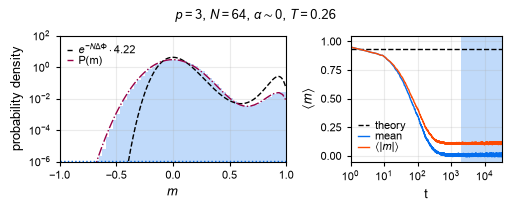

In [ ]:
N=64

with h5py.File(f"../_results/_traj_all/p3/N64/a0.0773_T0.1_m1_t100000/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])

df = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_p3_N64_T0.26_alpha0.0.csv")

n_steps = mt.shape[0]
trials = mt.shape[1]

cut = 30000
mdist = mt[-cut:, :].flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=True)
prob_m = counts#/len(mdist)

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

sns.histplot(x=bin_centers, bins=bin_edges.tolist(), weights=prob_m, color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25)

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("probability density")
ax[0].set_xlim(-1, 1)
#ax.set_ylim(2e-5, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
ax[0].set_yscale('log')

ax[0].axhline(np.min(prob_m[prob_m>0]), color='xkcd:cerulean blue', ls=':') #1/len(mdist)

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.26.csv")
qp = qp.filter((pl.col("alpha") == 0)) #0.0792733719109852))0.08539251882193688

data = np.exp(-qp['Phi'].to_numpy()*N)
y_data = qp['M'].to_numpy()
normalize = 1/np.sum(data*(qp['M'].to_numpy()[1:] - qp['M'].to_numpy()[:-1])[0])
exponent = np.floor(np.log10(normalize/data.max()))
pref = normalize/(10**exponent)
y_qp = data*normalize

ax[0].plot(qp['M'].to_numpy(), y_qp, 
        label=f"$e^{{-N\\Delta\\Phi}}\\cdot{pref:.2f}$", #\\times 10^{{ {exponent:.0f} }}$", 
        color="0", ls='--')

ax[0].plot(df['M'].to_numpy(), df['pi'].to_numpy()/(df['M'].to_numpy()[1:] - df['M'].to_numpy()[:-1])[0], label=f"P(m)", color='xkcd:purple red', ls='-.')

ax[0].legend(framealpha=0, loc = 'upper left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)
ax[0].set_ylim(1e-6, 100)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.8)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls='--', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[-cut], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, label='mean', color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$')

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 4, 5, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

ax[0].grid(alpha=0.25)
ax[1].grid(alpha=0.25)

fig.suptitle(f"$p=3$, $N={N}$, $\\alpha\\sim 0$, $T=0.26$")

#ax.set_ylim(0, 9)
plt.savefig(f'./final/distribution/p3_N{N}_a0_T0.26_LD.png', dpi=800, bbox_inches='tight')
plt.show()

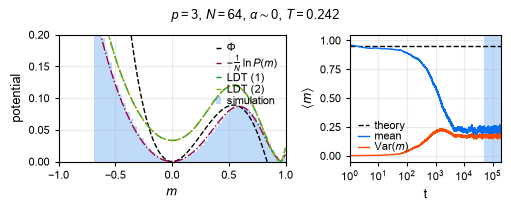

In [45]:
N=64

cut = 150000
with h5py.File(f"../_results/_traj_all/p3/N64/a0_T0.242_m1_t200000/traj.h5", 'r') as f:
    mmean = np.array(f['m_t_mean'])
    mabs = np.array(f['mabs_t_mean'])
    mvar = np.array(f['m_t_var'])
    mt = f['m_t'][-cut:, :].T

df = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_p3_N64_T0.242_alpha0.0.csv")
df2 = pl.read_csv("../Modules/HopfieldSim/_results/ldt/ssdist_case2_p3_N64_T0.242_alpha0.0.csv")

mdist = mt.flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
prob_m = counts/len(mdist)
mask = prob_m > 0

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

weights = -np.log(prob_m[mask])/N
sns.histplot(x=bin_centers[mask], bins=bin_edges.tolist(), weights=np.abs(weights - np.min(weights[:int(len(weights)/2)])), 
            color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25,
            label = 'simulation')

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("potential")
ax[0].set_xlim(-1, 1)
#ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
#ax[0].set_yscale('log')

#ax[0].axhline(-np.log(1/len(mdist))/N - np.min(weights), color='xkcd:cerulean blue', ls=':')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p3_T0.242.csv")
qp = qp.filter((pl.col("alpha") == 0)) #0.0792733719109852))0.08539251882193688

ax[0].plot(qp['M'].to_numpy(), qp['Phi'].to_numpy(), 
        label=f"$\\Phi$", 
        color="0", ls='--')

#pot_pi_raw = -np.log(df['pi'].to_numpy())/N
#ax[0].plot(df['M'].to_numpy(), pot_pi_raw - np.min(pot_pi_raw[:int(len(pot_pi_raw)/2)]), label="$-\\frac{1}{N}\\; \\ln P(m)$", color='xkcd:purple red', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_N0'].to_numpy(), label="$-\\frac{1}{N}\\; \\ln P(m)$", color='xkcd:purple red', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_LD1'].to_numpy(), 
           label="LDT (1)", color='xkcd:irish green', ls='-.')

ax[0].plot(df2['M'].to_numpy(), df2['V_LD'].to_numpy(), 
           label="LDT (2)", color='xkcd:pea green', ls='--')

ax[0].legend(framealpha=0, loc = 'upper right',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0.1)
ax[0].set_ylim(0, 0.2)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))
ax[0].set_yticks(np.arange(0, 0.21, 0.05))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.4)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls='--', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[-cut], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, label='mean', color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, mvar, color='xkcd:blood orange', label='Var($m$)') #$\\langle |m| \\rangle$

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 5, 6, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

ax[0].grid(alpha=0.25)
ax[1].grid(alpha=0.25)

fig.suptitle(f"$p=3$, $N={N}$, $\\alpha\\sim 0$, $T=0.242$")

#ax.set_ylim(0, 9)
plt.savefig(f'./final/potential/p3_N{N}_a0_T0.242_LD.png', dpi=800, bbox_inches='tight')
plt.show()

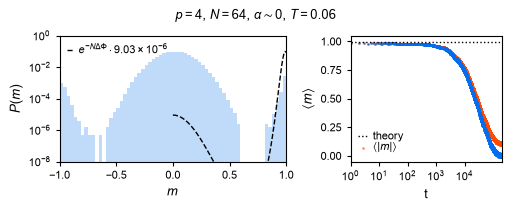

In [55]:
N=64

with h5py.File(f"../_results/_traj_all/p4/N64/a0_T0.06_m1_t2e5/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])

n_steps = mt.shape[0]
trials = mt.shape[1]

mdist = mt[cut:, :].flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
prob_m = counts/len(mdist)

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

sns.histplot(x=bin_centers, bins=bin_edges.tolist(), weights=prob_m, color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25)

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("$P(m)$")
ax[0].set_xlim(-1, 1)
#ax.set_ylim(2e-5, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
ax[0].set_yscale('log')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p4_T0.06.csv")
qp = qp.filter((pl.col("alpha") == 0))

data = np.exp(-qp['Phi'].to_numpy()*N)
#data -= data[0]
peak = np.max(prob_m)
exponent = np.floor(np.log10(peak/data.max()))
pref = peak/data.max()/(10**exponent)
y_qp = data*peak/data.max()

ax[0].plot(qp['M'].to_numpy(), y_qp, 
        label=f"$e^{{-N\\Delta\\Phi}}\\cdot{pref:.2f}\\times 10^{{ {exponent:.0f} }}$", 
        color="0", ls='--')

ax[0].legend(framealpha=0, loc = 'upper left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)
ax[0].set_ylim(1e-8, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.8)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls=':', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[cut], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].scatter(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$', s=1, edgecolor=None, alpha=0.5)
ax[1].scatter(steps, mmean, color='xkcd:cerulean blue', s=1, edgecolor=None, alpha=0.5) #, s=1)

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 4, 5, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 0.8, borderpad = 0.2,
          labelspacing = 0)

fig.suptitle(f"$p=4$, $N={N}$, $\\alpha\\sim 0$, $T=0.06$")

#ax.set_ylim(0, 9)
plt.savefig(f'/home/serim/Projects/HOPFIELD/_figures/final/distribution/p4_N{N}_K1_T0.06.png', dpi=800, bbox_inches='tight')
plt.show()

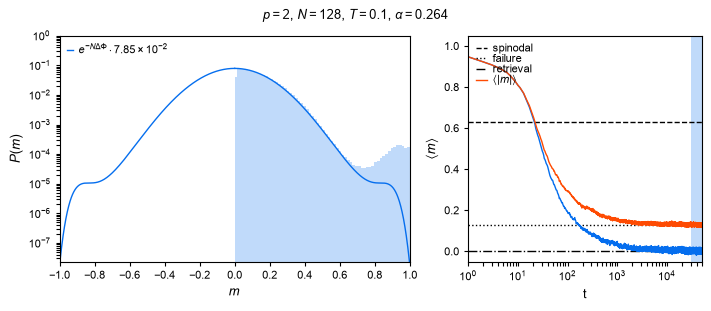

In [12]:
N=128

with h5py.File(f"..//_results/_traj_all/p2/N128/a0.264_T0.1_m1_t50000/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])

n_steps = mt.shape[0]
trials = mt.shape[1]

mdist = np.abs(mt[-20000:, :].flatten())
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
mask = counts != 0
prob_m = counts[mask]/len(mdist)

fig, ax = plt.subplots(ncols=2, figsize=(7, 3), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

sns.histplot(x=bin_centers[mask], bins=bin_edges.tolist(), weights=prob_m, color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25)

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("$P(m)$")
ax[0].set_xlim(-1, 1)
#ax.set_ylim(2e-5, 1)
ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
ax[0].set_yscale('log')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p2_T0.1.csv")
qp = qp.filter((pl.col("alpha") == 0.2629991261012574))

data = np.exp(-qp['Phi'].to_numpy()*N)
#data -= data[0]
peak = np.max(prob_m)
exponent = np.floor(np.log10(peak/data.max()))
pref = peak/data.max()/(10**exponent)
y_qp = data*peak/data.max()

ax[0].plot(qp['M'].to_numpy(), y_qp, 
        label=f"$e^{{-N\\Delta\\Phi}}\\cdot{pref:.2f}\\times 10^{{ {exponent:.0f} }}$", 
        color="xkcd:cerulean blue", ls='-')
ax[0].plot(-qp['M'].to_numpy(), data*peak/data.max(), 
        color="xkcd:cerulean blue", ls='-')

ax[0].legend(framealpha=0, loc = 'upper left',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0)

ax[0].set_ylim(np.min(y_qp), 1)

steps = np.arange(0, len(mmean))
ax[1].axhline(y=0.62937, color='0', ls='--', lw=1, label='spinodal')

mask1 = mdist<0.755
mask2 = mdist>=0.755

mdist_f = mdist[mask1]
mdist_r = mdist[mask2]

ax[1].axhline(y=np.sum(mdist_f)/len(mdist), color='0', ls=':', lw=1, label='failure')
ax[1].axhline(y=np.sum(mdist_r)/len(mdist), color='0', ls='-.', lw=1, label='retrieval')

ax[1].fill_betweenx([-0.05, 1.05], steps[-20000], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$')
ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
#ax[1].set_yscale('log')
ax[1].legend(framealpha=0, loc = 'upper left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

fig.suptitle(f"$p=2$, $N={N}$, $T=0.1$, $\\alpha=0.264$")

#ax.set_ylim(0, 9)
#plt.savefig(f'/home/serim/Projects/HOPFIELD/_figures/final/p2_N{N}_a0.264_T0.1.svg', dpi=800, bbox_inches='tight')
plt.show()

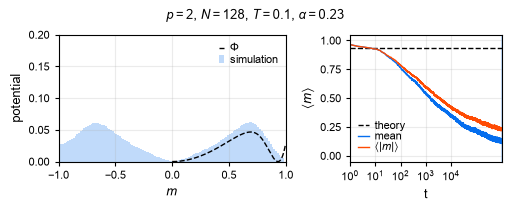

In [47]:
N=128

with h5py.File(f"..//_results/_traj_all/p2/N128/a0.23_T0.1_m1_t1000000/traj.h5", 'r') as f:
    mt = np.array(f['m_t'])[0].T
    mmean = np.array(f['m_t_mean'])
    mmax = np.array(f['mmax_t_mean'])
    mvar = np.array(f['m_t_var'])
    frac = np.array(f['m_t_retrieval_frac'])


n_steps = mt.shape[0]
trials = mt.shape[1]

cut = 30000
mdist = mt[-cut:, :].flatten()
counts, bin_edges = np.histogram(mdist, bins=N, range=(-1, 1), density=False)
prob_m = counts/len(mdist)
mask = prob_m > 0

fig, ax = plt.subplots(ncols=2, figsize=(5, 2), width_ratios=[3, 2],
                       constrained_layout=True)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

weights = -np.log(prob_m[mask])/N
sns.histplot(x=bin_centers[mask], bins=bin_edges.tolist(), weights=weights - np.min(weights), 
            color='xkcd:cerulean blue', edgecolor=None, ax=ax[0], alpha=0.25,
            label = 'simulation')

#plt.title("Distribution of m_t")
ax[0].set_xlabel("$m$")
ax[0].set_ylabel("potential")
ax[0].set_xlim(-1, 1)
#ax[0].set_xticks(np.arange(-1, 1.1, 0.2))
#ax[0].set_yscale('log')

#ax[0].axhline(-np.log(1/len(mdist))/N - np.min(weights), color='xkcd:cerulean blue', ls=':')

qp = pl.read_csv("../Modules/HopfieldSim/_results/quasipotential/quasip_p2_T0.1.csv")
qp = qp.filter((pl.col("alpha") == 0.23077384134760834))

ax[0].plot(qp['M'].to_numpy(), qp['Phi'].to_numpy(), 
        label=f"$\\Phi$", 
        color="0", ls='--')

ax[0].legend(framealpha=0, loc = 'upper right',
          handletextpad=0.5, handlelength = 0.5, borderpad = 0.2,
          labelspacing = 0.1)
ax[0].set_ylim(1e-8, 0.2)
ax[0].set_xticks(np.arange(-1, 1.1, 0.5))
ax[0].set_yticks(np.arange(0, 0.21, 0.05))

steps = np.arange(0, len(mmean))
spin_m = qp.filter((pl.col("M")>0.8)).sort("Phi")[0]["M"].to_numpy()[0]
ax[1].axhline(y=spin_m, color='0', ls='--', label='theory')

ax[1].fill_betweenx([-0.05, 1.05], steps[-cut], steps[-1], color='xkcd:cerulean blue', alpha=0.25, edgecolor=None)
ax[1].plot(steps, mmean, label='mean', color='xkcd:cerulean blue') #, s=1)
ax[1].plot(steps, np.mean(np.abs(mt), axis=1), color='xkcd:blood orange', label='$\\langle |m| \\rangle$')

ax[1].set_xscale('log')
ax[1].set_xlabel('t')
ax[1].set_ylabel('$\\langle m \\rangle$')
ax[1].set_xlim(steps[1], steps[-1])
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xticks(np.logspace(0, 4, 5, base=10))

ax[1].legend(framealpha=0, loc = 'lower left',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

ax[0].grid(alpha=0.25)
ax[1].grid(alpha=0.25)

fig.suptitle(f"$p=2$, $N={N}$, $T=0.1$, $\\alpha=0.23$")

#ax.set_ylim(0, 9)
plt.savefig(f'./final/potential/p2_N{N}_a0.23_T0.1.png', dpi=800, bbox_inches='tight')
plt.show()

In [277]:
qp.filter((pl.col("M")>0.5)).sort("Phi")#[0]["M"].to_numpy()[0]

p,T,alpha,M,Phi
i64,f64,f64,f64,f64
2,0.1,0.246886,0.500498,0.03489
2,0.1,0.246886,0.501497,0.035011
2,0.1,0.246886,0.502496,0.035133
2,0.1,0.246886,0.503495,0.035254
2,0.1,0.246886,0.504494,0.035376
…,…,…,…,…
2,0.1,0.246886,0.994004,0.073934
2,0.1,0.246886,0.995003,0.074861
2,0.1,0.246886,0.996002,0.075806


# SUPPLEMENTAL FIGURES

## N-dependence

./final/fig2-aT/LDT_p3p4.png


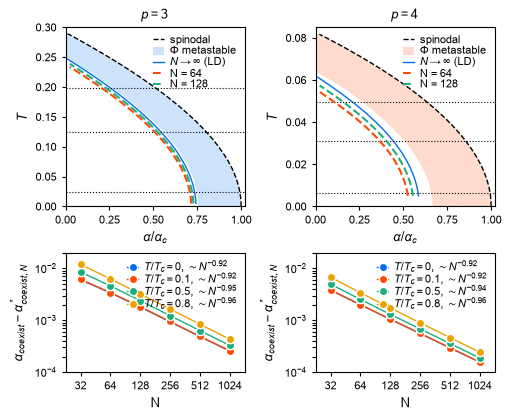

In [45]:
import pandas as pd

D = "../Modules/HopfieldSim/_results/ldt"
C = ["xkcd:cerulean blue", "xkcd:blood orange", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK, MUTED = "0", "0"

conv = pd.read_csv(os.path.join(D, "coex_finiteN.csv"))
fig, axes = plt.subplots(2, 2, figsize=(5, 5), layout='compressed',
                         width_ratios=[1, 1], height_ratios=[3, 2])

acs = [0.126, 0.033]
Tc = [0.3, 0.085]

for j, p in enumerate((3, 4)):
    pb = pd.read_csv(os.path.join(D, f"ld_phase_boundary_p{p}.csv"))
    cp = conv[conv.p == p]

    ax = axes[0, j]
    ax.plot(aT_quasip[f'p{p}_spinodal']/acs[j], aT_quasip[f'p{p}_T'], label = 'spinodal',
                    color='0', ls = '--', dash_joinstyle = 'bevel', alpha=1)
    #ax.plot(aT_quasip[f'p{p}_coexist']/acs[j], aT_quasip[f'p{p}_T'], label = 'coexistence',
    #            color='0', ls = '-', dash_joinstyle = 'bevel', alpha=1, lw=1.5)
    ax.fill_betweenx(aT_quasip[f'p{p}_T'], aT_quasip[f'p{p}_spinodal']/acs[j], aT_quasip[f'p{p}_coexist']/acs[j], color=C[j], alpha=0.2, label = r'$\Phi$ metastable', edgecolor='none')

    if p==3:
        ax.fill_betweenx(aT_quasip[f'p{p}_T'][119:], 0, aT_quasip[f'p{p}_spinodal'][119:]/acs[j], color=C[j], alpha=0.2, edgecolor='none')
    if p==4:
        ax.fill_betweenx(aT_quasip[f'p{p}_T'][109:], 0, aT_quasip[f'p{p}_spinodal'][109:]/acs[j], color=C[j], alpha=0.2, edgecolor='none')

    ax.plot(pb.alpha_coexistence/acs[j], pb["T"], color=C[0], label=r"$N\to\infty$ (LD)")

    for k, col in enumerate(c for c in pb.columns if c.startswith("alpha_coex_N")):
        ax.plot(pb[col]/acs[j], pb["T"], color=C[k + 1], lw=1.5, ls="--",
                label=f"N = {col.removeprefix('alpha_coex_N')}", zorder=3)
        
    for fr, g in cp.groupby("T_over_Tc"):
        T = g["T"].iloc[0]
        ax.axhline(T, color=MUTED, lw=0.8, ls=":")
        #ax.annotate(rf"$T/T_c={fr:g}$", (0, T), xytext=(3, 2),
        #            textcoords="offset points", color=MUTED, fontsize=8)
        
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, Tc[j])
    ax.set_xlabel(r"$\alpha/\alpha_c$"); ax.set_ylabel("$T$")
    ax.set_title(f"$p = {p}$", color=INK)

    ax.legend(framealpha=0, loc = 'upper right',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)

    ax.set_aspect(1.02/Tc[j])

    ax = axes[1, j]
    for k, (fr, g) in enumerate(cp.groupby("T_over_Tc")):
        g = g.dropna(subset=["alpha_N"])
        gap = g.alpha_inf - g.alpha_N
        ok = gap > 0
        slope = np.polyfit(np.log(g.N[ok]), np.log(gap[ok]), 1)[0] if ok.sum() >= 2 else np.nan
        ax.plot(np.log2(g.N[ok]), gap[ok], "o-", color=C[k], mec='1',
                  label=rf"$T/T_c={fr:>2g}$, $\sim N^{{{slope:.2f}}}$")

    ax.set_xlim(4.5, 10.5)
    
    ax.set_yscale("log")
    ax.set_xticks(np.log2([32, 64, 128, 256, 512, 1024]), labels=[32, 64, 128, 256, 512, 1024])

    ax.set_xlabel("N")
    ax.set_ylabel(r"$\alpha_{coexist} - \alpha^*_{coexist, N}$")

    ax.legend(framealpha=0, loc = 'upper right',
          handletextpad=0.5, handlelength = 1, borderpad = 0.2,
          labelspacing = 0)
    ax.set_box_aspect(2/3)

axes[1, 0].set_ylim(1e-4, 2e-2) 
axes[1, 1].set_ylim(1e-4, 2e-2) 

save_dir='./final/fig2-aT/'
name = f'LDT_p3p4'
format = '.png'

print(save_dir+name+format)
plt.savefig(save_dir+name+format, dpi=800, pad_inches=0.02, bbox_inches='tight')
plt.show()